# MHW red-noise model of B, and extensions

Replicates Masato, Hoskins & Woollings (2009), then tries AR(2) and a two-timescale model. Uses the daily B saved by `B Value Computation.ipynb` (run that first).

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

B_daily = pd.read_parquet("../results/ERA40_B_index_daily_1957-2002_TH08.parquet").rename(columns=int)   # rows = days, columns = longitude (°E)
print(B_daily.shape, B_daily.index[0].date(), "to", B_daily.index[-1].date())

(16436, 72) 1957-09-01 to 2002-08-31


## Winter ΔB

DJF days of the 44 winters 1957/58 – 2000/01. ΔB = B minus its winter median at each longitude (MHW use the median).

In [10]:
WINTERS = range(1958, 2002)   # labelled by January
lons = B_daily.columns.to_numpy()
N_LON = len(lons)

B_winters = [B_daily.loc[f"{y-1}-12":f"{y}-02"].to_numpy() for y in WINTERS]   # (days, longitudes) per winter
B_median = np.median(np.concatenate(B_winters), axis=0)
dB_winters = [b - B_median for b in B_winters]

## Observed correlations

Correlation in time at lags 1–20 days (pairs never span two winters), averaged over longitude since MHW use one φ everywhere; and correlation between longitudes 0°, 5°, …, 100° apart.

In [11]:
def lag_corr(series_list, k):
    num = sum((x[:-k] * x[k:]).sum(axis=0) for x in series_list)
    den = sum((x ** 2).sum(axis=0) for x in series_list)
    return num / den

mu = np.concatenate(dB_winters).mean(axis=0)
centred = [x - mu for x in dB_winters]
time_lags = np.arange(1, 21)
obs_acf = np.array([lag_corr(centred, k).mean() for k in time_lags])
r1, r2 = obs_acf[0], obs_acf[1]
obs_var = np.concatenate(centred).var(axis=0).mean()

X = np.concatenate(centred)
X = X / X.std(axis=0)
space_lags = np.arange(21)   # in steps of 5 degrees
obs_space = np.array([(X * np.roll(X, -m, axis=1)).mean() for m in space_lags])

print(f"lag 1 = {r1:.3f}, lag 2 = {r2:.3f}  (AR(1) would give lag 2 = {r1**2:.3f})")

lag 1 = 0.635, lag 2 = 0.367  (AR(1) would give lag 2 = 0.403)


## Models

MHW 2D model: ΔB*ₙ = Σ φᵢ ΔBₙ₋ᵢ + εₙ, then ΔBₙ = A ΔB*ₙ.
- AR(1): one φ (MHW).
- AR(2): φ₁, φ₂.
- Two timescales: ΔB = fast AR(1) + slow AR(1), each run through A with its own noise.

A links each longitude to its 3 neighbours on each side, rows summing to 1 (MHW picked its values by hand). A also shortens the memory, so the time parameters and A are fitted together: the model's own correlation in time (AR(1): lag 1; AR(2): lags 1–2; two timescales: lags 1–20) and across longitude match the data. Noise sizes are set so ΔB has the observed variance.

In [12]:
from scipy.optimize import minimize, least_squares

def make_A(w):
    """72x72 matrix: weight 1 on the diagonal, w[j-1] for neighbours j = 1, 2, 3 on each side; rows sum to 1."""
    A = np.eye(N_LON)
    for j, weight in enumerate(w, start=1):
        A += weight * (np.roll(np.eye(N_LON), j, axis=1) + np.roll(np.eye(N_LON), -j, axis=1))
    return A / A.sum(axis=1, keepdims=True)

def mode_stats(phis, A):
    """For unit noise, per Fourier mode in longitude: variance and correlation in time at lags 0-20.
    None if the model is unstable."""
    lam = np.fft.fft(A[0]).real                       # eigenvalues of A
    a1 = lam * phis[0]
    a2 = lam * phis[1] if len(phis) > 1 else np.zeros(N_LON)
    if not np.all((a2 + np.abs(a1) < 1) & (np.abs(a2) < 1)):
        return None
    g0 = lam**2 * (1 - a2) / ((1 + a2) * ((1 - a2)**2 - a1**2))
    rho = [np.ones(N_LON), a1 / (1 - a2)]
    for k in range(2, time_lags[-1] + 1):
        rho.append(a1 * rho[-1] + a2 * rho[-2])
    return g0, np.array(rho)

def model_stats(components, A):
    """components: list of (phis, share of variance). Returns correlation in time (lags 1-20),
    correlation across longitude, and each component's variance for unit noise."""
    g0_tot, rho_tot, unit_vars = 0, 0, []
    for phis, share in components:
        stats = mode_stats(phis, A)
        if stats is None:
            return None
        g0, rho = stats
        unit_vars.append(g0.sum() / N_LON)
        g0 = g0 * share / unit_vars[-1]               # scale this component to its share of the variance
        g0_tot, rho_tot = g0_tot + g0, rho_tot + g0 * rho
    acf = rho_tot[1:].sum(axis=1) / g0_tot.sum()
    k = np.arange(N_LON)
    space = np.array([(g0_tot * np.cos(2 * np.pi * k * m / N_LON)).sum() for m in space_lags]) / g0_tot.sum()
    return acf, space, unit_vars

def fit_model(make_components, x0, bounds, n_lags):
    """Fit the time parameters and A's neighbour weights together, so the model's own correlation in time
    (lags 1..n_lags) and across longitude match the observations."""
    n = len(x0)
    def residuals(q):
        stats = model_stats(make_components(q[:n]), make_A(q[n:]))
        if stats is None:
            return np.full(n_lags + len(space_lags), 10.0)
        acf, space, _ = stats
        return np.concatenate([acf[:n_lags] - obs_acf[:n_lags], space - obs_space])
    lo, hi = zip(*(bounds + [(0, 5)] * 3))
    q = least_squares(residuals, list(x0) + [0.5, 0.2, 0.1], bounds=(lo, hi)).x
    return make_components(q[:n]), make_A(q[n:])

# name: (parameters -> list of (phis, share of variance), starting values, bounds, lags to match)
model_specs = {
    "AR(1) (MHW)":    (lambda q: [([q[0]], 1.0)], [r1], [(0, 1)], 1),
    "AR(2)":          (lambda q: [([q[0], q[1]], 1.0)], [r1, 0.0], [(-2, 2), (-1, 1)], 2),
    "Two timescales": (lambda q: [([q[1]], q[0]), ([q[2]], 1 - q[0])], [0.7, 0.5, 0.9], [(0, 1)] * 3, 20),
}

fits = {}
for name, spec in model_specs.items():
    components, A = fit_model(*spec)
    acf, space, unit_vars = model_stats(components, A)
    sigmas = [np.sqrt(s * obs_var / v) for (_, s), v in zip(components, unit_vars)]
    fits[name] = dict(components=components, A=A, sigmas=sigmas, acf=acf, space=space)
    print(f"{name}: phis = {[np.round(ph, 3).tolist() for ph, _ in components]}, "
          f"shares = {[round(float(s), 2) for _, s in components]}, A row = {np.round(A[0, :4], 3)}")

AR(1) (MHW): phis = [[0.759]], shares = [1.0], A row = [0.296 0.217 0.074 0.061]
AR(2): phis = [[0.845, -0.129]], shares = [1.0], A row = [0.294 0.215 0.072 0.066]
Two timescales: phis = [[0.567], [0.892]], shares = [0.6, 0.4], A row = [0.3   0.211 0.09  0.049]


Check against MHW Fig. 1: model vs observed correlation in time and across longitude.

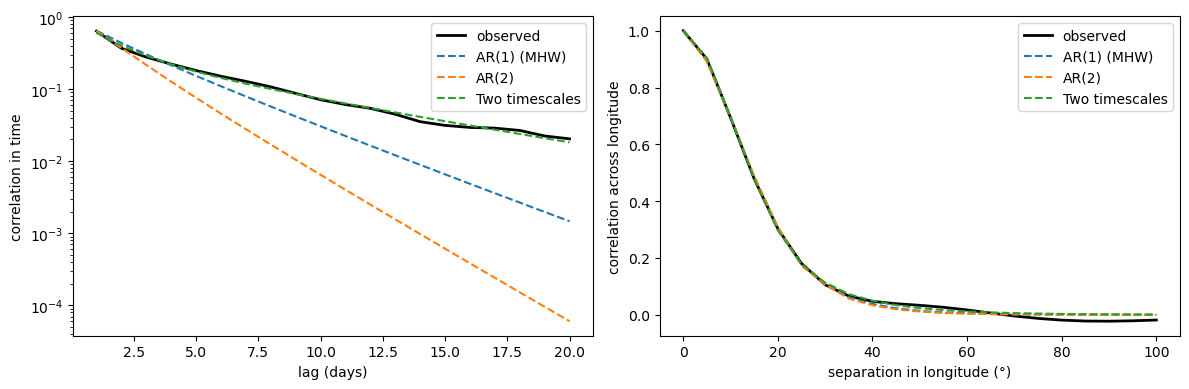

In [13]:
colors = {"AR(1) (MHW)": "tab:blue", "AR(2)": "tab:orange", "Two timescales": "tab:green"}

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(time_lags, obs_acf, color="black", linewidth=2, label="observed")
for name, f in fits.items():
    axes[0].plot(time_lags, f["acf"], "--", color=colors[name], label=name)
axes[0].set_xlabel("lag (days)")
axes[0].set_ylabel("correlation in time")
axes[0].set_yscale("log")
axes[0].legend()
axes[1].plot(5 * space_lags, obs_space, color="black", linewidth=2, label="observed")
for name, f in fits.items():
    axes[1].plot(5 * space_lags, f["space"], "--", color=colors[name], label=name)
axes[1].set_xlabel("separation in longitude (°)")
axes[1].set_ylabel("correlation across longitude")
axes[1].legend()
plt.tight_layout()
plt.show()

## Simulation

50 runs, each 44 winters of 90 days (as in MHW); the winter median of B is added back.

In [14]:
N_RUNS, N_DAYS, BURN_IN = 50, 90, 60

def simulate_run(fit, rng):
    """B for one run: (winters, days, longitudes). Sum of the model's components."""
    T = BURN_IN + N_DAYS
    total = np.zeros((len(WINTERS), T, N_LON))
    for (phis, _), sigma in zip(fit["components"], fit["sigmas"]):
        x = np.zeros((len(WINTERS), T, N_LON))
        eps = sigma * rng.standard_normal((len(WINTERS), T, N_LON))
        for t in range(len(phis), T):
            x_star = eps[:, t] + sum(phi * x[:, t - i - 1] for i, phi in enumerate(phis))
            x[:, t] = x_star @ fit["A"].T
        total += x
    return total[:, BURN_IN:] + B_median

## LIB, SB and SBE frequencies (MHW Fig. 2)

LIB: B > 0. SB: LIB at 3 neighbouring longitudes inside the 45° sector centred on that longitude. SBE: SB on at least 5 consecutive days.

In [15]:
def blocking_flags(B):
    """B: (days, longitudes) for one winter -> LIB, SB, SBE as boolean arrays."""
    lib = B > 0
    run = lib & np.roll(lib, 1, axis=1) & np.roll(lib, -1, axis=1)   # centre of 3 LIB longitudes in a row
    sb = np.zeros_like(lib)
    for k in range(-3, 4):          # run centre within 15°, so all 3 points lie in the sector L-20 ... L+20
        sb |= np.roll(run, k, axis=1)
    # length of the SB spell each day belongs to
    fwd, bwd = np.zeros(sb.shape, int), np.zeros(sb.shape, int)
    for t in range(len(sb)):
        fwd[t] = sb[t] * (fwd[t - 1] + 1 if t > 0 else 1)
    for t in reversed(range(len(sb))):
        bwd[t] = sb[t] * (bwd[t + 1] + 1 if t < len(sb) - 1 else 1)
    sbe = sb & (fwd + bwd - 1 >= 5)
    return lib, sb, sbe

def frequencies(winters):
    """Fraction of days with LIB, SB, SBE at each longitude."""
    flags = [blocking_flags(B) for B in winters]
    return {name: np.concatenate([f[i] for f in flags]).mean(axis=0) for i, name in enumerate(["LIB", "SB", "SBE"])}

rng = np.random.default_rng(0)
freq_obs = frequencies(B_winters)
freq_runs = {name: [frequencies(simulate_run(f, rng)) for _ in range(N_RUNS)]
             for name, f in fits.items()}

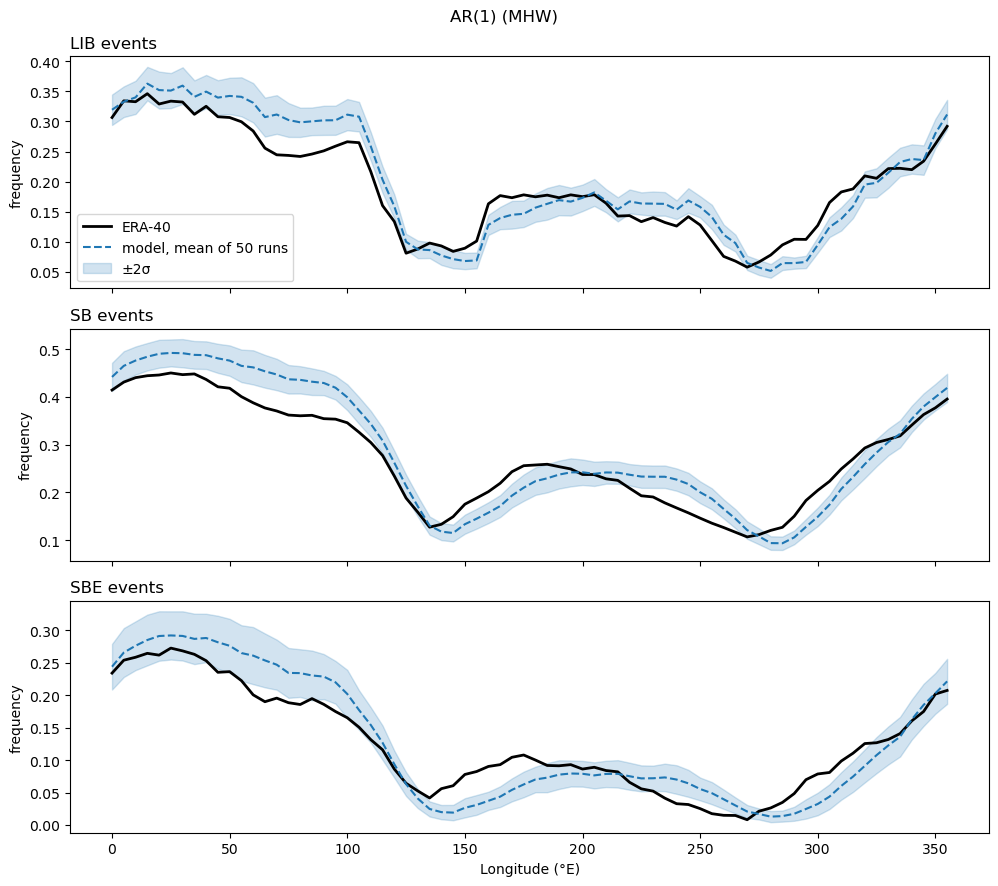

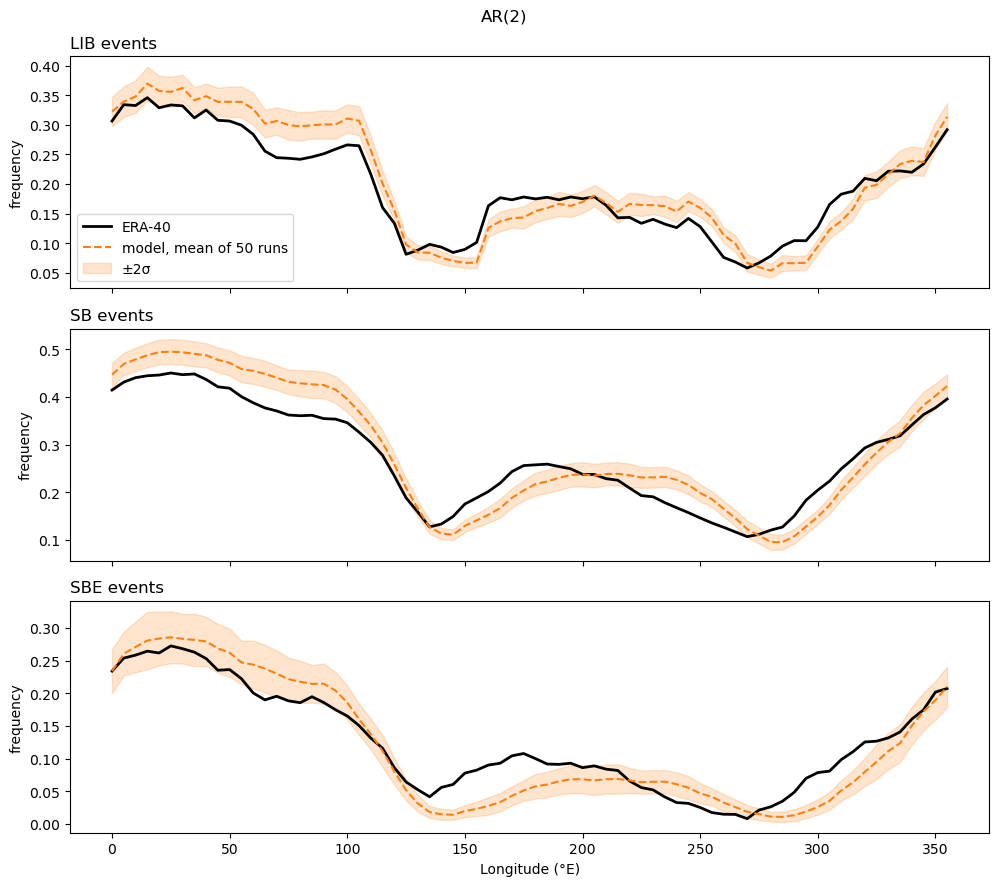

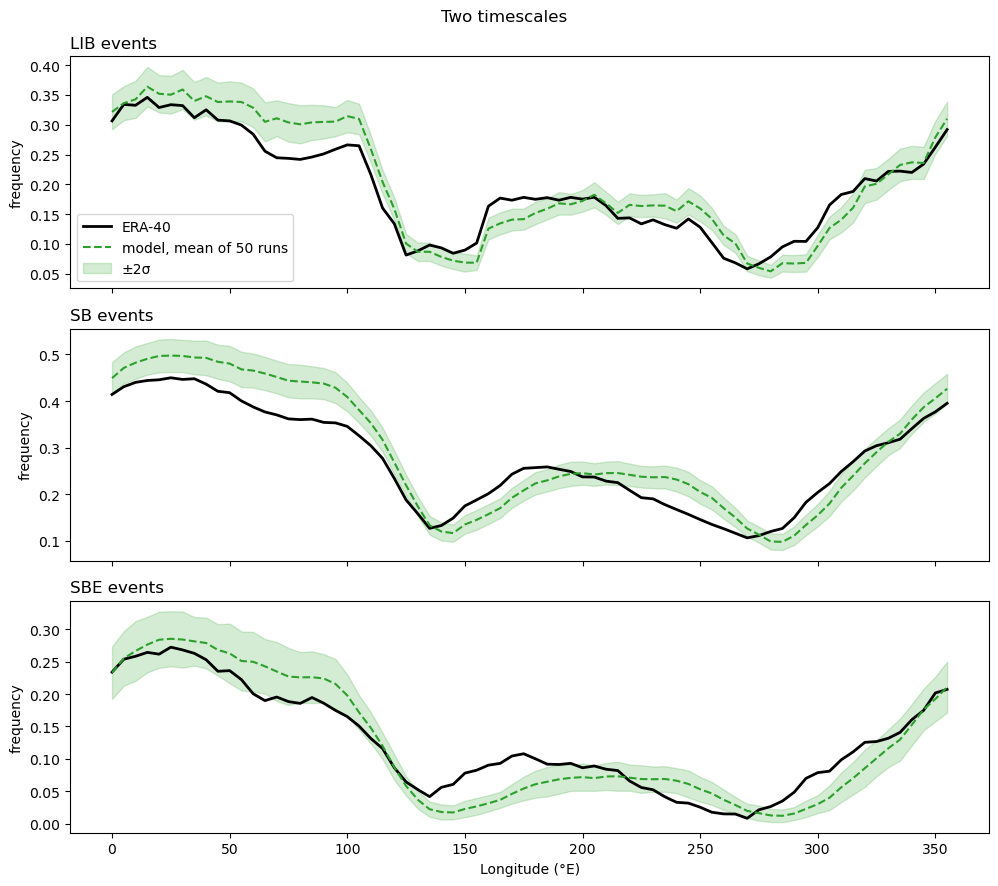

In [16]:
for name, runs in freq_runs.items():
    fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True)
    fig.suptitle(name)
    for ax, measure in zip(axes, ["LIB", "SB", "SBE"]):
        vals = np.array([r[measure] for r in runs])
        mean, sd = vals.mean(axis=0), vals.std(axis=0)
        ax.plot(lons, freq_obs[measure], color="black", linewidth=2, label="ERA-40")
        ax.plot(lons, mean, "--", color=colors[name], label=f"model, mean of {N_RUNS} runs")
        ax.fill_between(lons, mean - 2 * sd, mean + 2 * sd, color=colors[name], alpha=0.2, label="±2σ")
        ax.set_ylabel("frequency")
        ax.set_title(f"{measure} events", loc="left")
    axes[0].legend()
    axes[-1].set_xlabel("Longitude (°E)")
    plt.tight_layout()
    plt.show()